# Advanced calculations

Composing several calculations: an LMTD correction factor for a shell-and-tube exchanger, a
packed-column hydraulic rating across its operating window, and a property table taken from a
flash. Each result still carries its own warnings and provenance.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

import azoth
import azoth.eos
import azoth.hydraulics
import azoth.thermal
from azoth.eos.components import mixture_of

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity

## LMTD correction factor

For a 1-2 shell-and-tube exchanger, `ft` corrects the counter-current LMTD. `R` and `P` are the
capacity-rate and temperature ratios; `required_shell_passes` says how many shell passes the
0.75 rule asks for.

In [2]:
hot_in, hot_out, cold_in, cold_out = q(400.0, "K"), q(350.0, "K"), q(300.0, "K"), q(330.0, "K")
lmtd = azoth.thermal.lmtd_correction_factor(hot_in, hot_out, cold_in, cold_out)

for name in ("r", "p", "ft", "ft_1_shell_pass", "ft_2_shell_passes", "required_shell_passes"):
    label = name.replace("_", " ")
    print(f"{label:>22}: {getattr(lmtd, name):.4f}")

                     r: 1.6667
                     p: 0.3000
                    ft: 0.9242
       ft 1 shell pass: 0.9242
     ft 2 shell passes: 0.9820
 required shell passes: 1.0000


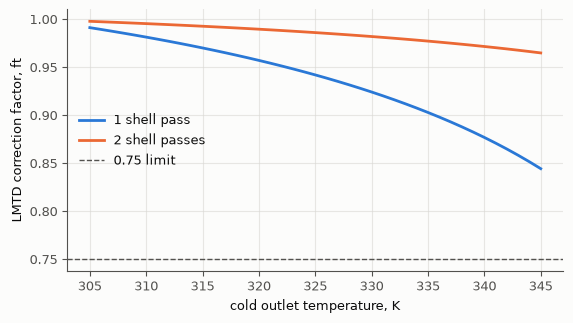

In [3]:
outlets = np.linspace(305.0, 345.0, 41)
one, two = [], []
for outlet in outlets:
    result = azoth.thermal.lmtd_correction_factor(hot_in, hot_out, cold_in, q(float(outlet), "K"))
    one.append(result.ft_1_shell_pass)
    two.append(result.ft_2_shell_passes)

fig, ax = plt.subplots()
ax.plot(outlets, one, color=PALETTE[0], label="1 shell pass")
ax.plot(outlets, two, color=PALETTE[1], label="2 shell passes")
ax.axhline(0.75, color=MUTED, linestyle="--", linewidth=1.0, label="0.75 limit")
ax.set_xlabel("cold outlet temperature, K")
ax.set_ylabel("LMTD correction factor, ft")
ax.legend(frameon=False)
plt.show()
plt.close(fig)

## Packed-column sizing

`packing_sizing` uses a flooding correlation to pick a diameter at a design flood fraction.
The packing name resolves from the databank by normalised display name.

In [4]:
sizing = azoth.hydraulics.packing_sizing(
    "Pall-Ring-50",
    0.7,
    q(1.0, "kg/s"),
    q(10.0, "kg/s"),
    q(1.2, "kg/m**3"),
    q(998.0, "kg/m**3"),
    q(1e-3, "Pa*s"),
    0.763,
)
print("packing:", sizing.packing_name)
print(f"required diameter: {sizing.required_diameter.to('m').magnitude:.3f} m")
print(f"selected diameter: {sizing.column_diameter.to('m').magnitude:.3f} m")
print(f"flooding velocity: {sizing.flooding_velocity.to('m/s').magnitude:.2f} m/s")

packing: Pall-Ring-50
required diameter: 0.859 m
selected diameter: 0.900 m
flooding velocity: 2.05 m/s


## The operating window

Rating the sized bed at a range of vapour loads. `design_ok` is false at both ends: too little
load does not wet the packing, too much floods it.

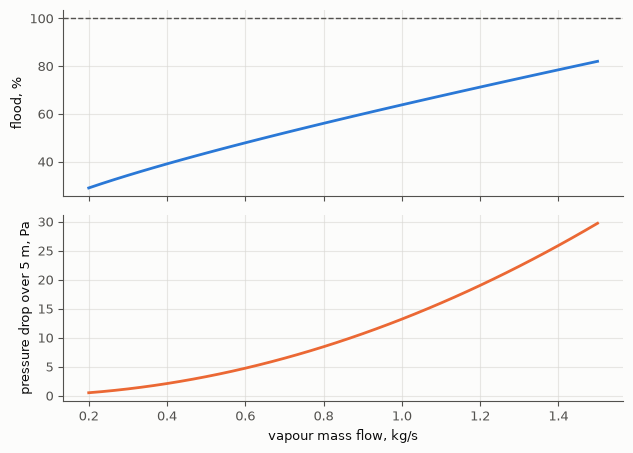

design window: 0.43 to 1.43 kg/s


In [5]:
diameter = sizing.column_diameter
loads = np.linspace(0.2, 1.5, 40)
flood, drop, ok = [], [], []
for load in loads:
    result = azoth.hydraulics.packing_hydraulics(
        "Pall-Ring-50",
        diameter,
        q(5.0, "m"),
        q(float(load), "kg/s"),
        q(10.0, "kg/s"),
        q(1.2, "kg/m**3"),
        q(998.0, "kg/m**3"),
        q(1.2e-5, "Pa*s"),
        q(1e-3, "Pa*s"),
        q(0.02, "N/m"),
        q(1e-5, "m**2/s"),
        q(1e-9, "m**2/s"),
        0.763,
    )
    flood.append(result.percent_flood)
    drop.append(result.total_pressure_drop.to("Pa").magnitude)
    ok.append(result.design_ok)

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.6))
top.plot(loads, flood, color=PALETTE[0])
top.axhline(100.0, color=MUTED, linestyle="--", linewidth=1.0)
top.set_ylabel("flood, %")
bottom.plot(loads, drop, color=PALETTE[1])
bottom.set_xlabel("vapour mass flow, kg/s")
bottom.set_ylabel("pressure drop over 5 m, Pa")
plt.tight_layout()
plt.show()
plt.close(fig)

window = [float(load) for load, good in zip(loads, ok, strict=True) if good]
print(f"design window: {min(window):.2f} to {max(window):.2f} kg/s")

In [6]:
design = azoth.hydraulics.packing_hydraulics(
    "Pall-Ring-50",
    diameter,
    q(5.0, "m"),
    q(1.0, "kg/s"),
    q(10.0, "kg/s"),
    q(1.2, "kg/m**3"),
    q(998.0, "kg/m**3"),
    q(1.2e-5, "Pa*s"),
    q(1e-3, "Pa*s"),
    q(0.02, "N/m"),
    q(1e-5, "m**2/s"),
    q(1e-9, "m**2/s"),
    0.763,
)
print(f"HTU overall: {design.hetp.to('m').magnitude:.2f} m")
print(f"theoretical stages in 5 m: {design.theoretical_stages:.2f}")
print("wetted:", design.wetting_ok, "| design ok:", design.design_ok)

HTU overall: 1.44 m
theoretical stages in 5 m: 3.47
wetted: True | design ok: True


## A property table from a flash

The liquid property calls share the flash roots, so the table is one state rather than four
independent correlations.

In [7]:
mix, ideal = mixture_of(["methane", "n-butane"])
z = [0.9, 0.1]
T, P = q(250.0, "K"), q(20.0, "bar")
flash = azoth.eos.pt_flash(mix, T, P, z)

liquid = azoth.eos.molar_enthalpy_entropy(mix, ideal, T, P, list(flash.x), flash.z_liquid)
viscosity = azoth.eos.viscosity(mix, T, P, list(flash.x))
conductivity = azoth.eos.thermal_conductivity(mix, ideal, T, P, list(flash.x))

print(f"phase:            {flash.phase}")
print(f"liquid h:         {liquid.h.to('kJ/mol').magnitude:.3f} kJ/mol")
print(f"liquid cp:        {liquid.cp.to('J/(mol*K)').magnitude:.1f} J/(mol*K)")
print(f"liquid viscosity: {viscosity.mu.to('mPa*s').magnitude:.3f} mPa*s")
print(f"liquid k:         {conductivity.k.to('W/(m*K)').magnitude:.3f} W/(m*K)")

phase:            two_phase
liquid h:         -22.425 kJ/mol
liquid cp:        114.5 J/(mol*K)
liquid viscosity: 0.211 mPa*s
liquid k:         0.115 W/(m*K)


## A check that did not run

A range check that could not evaluate its input reports `RANGE_CHECK_SKIPPED`, and the
provenance block carries the field. "Checked and fine" and "never checked" are different
states, and the result keeps them apart.

In [8]:
unchecked = azoth.hydraulics.darcy_weisbach(
    0.02, q(100.0, "m"), q(0.1, "m"), q(998.0, "kg/m**3"), q(1.5, "m/s")
)
print("warnings:", [warning.code.value for warning in unchecked.warnings])
print("skipped:", unchecked.provenance.skipped_checks)
print("clean:", unchecked.provenance.clean)

warnings: ['RANGE_CHECK_SKIPPED']
skipped: ('re',)
clean: False


In [9]:
print(json.dumps(json.loads(unchecked.to_json())["provenance"], indent=2))

{
  "calc_id": "hydraulics.darcy_weisbach",
  "clean": false,
  "name": "Darcy-Weisbach pressure drop",
  "python_path": "python/src/azoth/hydraulics/reference/darcy_weisbach.py",
  "python_sha256": "bc58e0c3099a8a3d2d455051e79f7f740048e760ccc66ea50e5a4943416601ec",
  "rust_path": "crates/azoth-hydraulics/src/darcy_weisbach.rs",
  "rust_sha256": "545fbab9e66481f673f2c8fba273fabdcaed2d20cf2b9ab33aa063996739915c",
  "skipped_checks": [
    "re"
  ],
  "source": "Crane TP-410",
  "spec_path": "specs/calcs/hydraulics/darcy_weisbach.toml",
  "spec_sha256": "034066c6179089039cb53a2cf080e9e4da82926dc1f05caabf506caf392aa2c0",
  "tests_active": 4,
  "tests_skipped": 2,
  "validation_cases": 1,
  "verification": "source_needed",
  "warning_codes": [
    "RANGE_CHECK_SKIPPED"
  ]
}


## Next

- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
- The generated pages for
  [`lmtd_correction_factor`](https://patrickmockridge.github.io/azoth/manual/thermal/lmtd_correction_factor.html)
  and [`packing_hydraulics`](https://patrickmockridge.github.io/azoth/manual/hydraulics/packing_hydraulics.html).